# Limpieza y analisis EDA del concentrado de hogares


## Integrantes

Oswaldo Ramirez Alvares

Jorge Ivàn Gutièrrez Amezcua

Diego Alejandro Solis Guadarrama

In [1]:
# Importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

pd.set_option('display.max_columns', None)

In [2]:
# Seleccionar columnas de utilidad
cols = ['folioviv', 'foliohog', 'ubica_geo', 'tam_loc', 'est_socio', 'clase_hog', 'sexo_jefe','edad_jefe',
        'educa_jefe', 'tot_integ', 'hombres', 'mujeres', 'mayores', 'menores', 'p12_64', 'p65mas', 'ocupados',
        'percep_ing', 'perc_ocupa', 'ing_cor', 'trabajo', 'sueldos', 'horas_extr', 'comisiones',
        'aguinaldo', 'indemtrab', 'otra_rem', 'industria', 'comercio', 'servicios', 'agricolas', 'pecuarios',
        'reproducc', 'pesca', 'otros_trab', 'rentas', 'jubilacion', 'becas', 'donativos', 'remesas',
        'bene_gob', 'transf_hog', 'trans_inst', 'negocio']
cols
# Traer datos
hogares = pd.read_csv('/run/media/oswal/01DD260F5154F4B0/Duend/Documentos/1 IA y ciencia de datos/Semestre 3/proyecto integrador/Raw data/conjunto_de_datos_enigh2024_ns_csv/conjunto_de_datos_concentradohogar_enigh2024_ns/conjunto_de_datos/conjunto_de_datos_concentradohogar_enigh2024_ns.csv', encoding='latin-1', usecols=cols)
hogares .head(10)

,folioviv,foliohog,ubica_geo,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,hombres,mujeres,mayores,menores,p12_64,p65mas,ocupados,percep_ing,perc_ocupa,ing_cor,trabajo,sueldos,horas_extr,comisiones,aguinaldo,indemtrab,otra_rem,negocio,industria,comercio,servicios,agricolas,pecuarios,reproducc,pesca,otros_trab,rentas,jubilacion,becas,donativos,remesas,bene_gob,transf_hog,trans_inst
0,100001901,1,1001,1,3,2,1,32,6,4,2,2,2,2,2,0,2,2,2,138232.38,130518.10,78299.99,18195.64,0.00,9048.90,0.00,4402.17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,7714.28,0.00
1,100001902,1,1001,1,3,2,1,48,9,4,2,2,4,0,4,0,2,2,2,118014.04,103829.72,76304.34,0.00,0.00,9782.60,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,2571.42,0.00
2,100001904,1,1001,1,3,2,2,60,6,2,1,1,2,0,2,0,2,2,2,46866.32,45580.61,41086.94,0.00,0.00,122.28,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,1285.71,0.00
3,100001905,1,1001,1,3,2,1,43,8,4,3,1,4,0,4,0,3,3,3,110430.10,97169.95,70923.89,586.95,0.00,3668.47,0.00,4402.17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00,195.64
4,100002501,1,1001,1,2,2,2,29,8,4,1,3,2,2,2,0,2,2,2,99494.12,93687.67,57975.64,1956.52,0.00,13695.64,0.00,6945.64,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
5,100002502,1,1001,1,2,2,1,30,8,4,3,1,3,1,3,0,3,3,3,119559.08,110484.26,76010.86,5502.71,1173.91,6603.24,0.00,20062.14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,1816.76,0.00
6,100002504,1,1001,1,2,2,1,28,6,4,2,2,2,2,2,0,2,2,2,78830.79,67110.07,54684.77,0.00,10907.60,489.13,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,5914.27,0.00
7,100002505,1,1001,1,2,2,1,33,9,4,1,3,2,2,2,0,1,1,1,41394.62,35266.30,0.00,0.00,35266.30,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2934.78,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
8,100002506,1,1001,1,2,2,1,48,10,3,1,2,2,1,2,0,1,2,1,58162.55,43972.79,38152.17,0.00,0.00,733.69,2445.65,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7581.51,0.0,0.0,0.0,0.0,978.26,0.00,0.00,5629.99
9,100003701,1,1001,1,2,2,1,55,4,4,3,1,4,0,4,0,2,3,2,102540.94,81491.76,64918.02,0.00,6737.70,3934.41,0.00,5901.63,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00,3049.18,0.00,0.00


In [3]:
hogares.tail()

,folioviv,foliohog,ubica_geo,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,hombres,mujeres,mayores,menores,p12_64,p65mas,ocupados,percep_ing,perc_ocupa,ing_cor,trabajo,sueldos,horas_extr,comisiones,aguinaldo,indemtrab,otra_rem,negocio,industria,comercio,servicios,agricolas,pecuarios,reproducc,pesca,otros_trab,rentas,jubilacion,becas,donativos,remesas,bene_gob,transf_hog,trans_inst
91409,3260593814,1,32052,4,2,2,1,47,4,3,1,2,3,0,3,0,2,2,2,40111.46,36511.46,36511.46,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
91410,3260593815,1,32052,4,2,2,1,31,10,5,3,2,2,3,2,0,2,2,2,87698.33,84098.33,70819.66,0.0,0.0,10327.86,0.0,2950.81,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
91411,3260593816,1,32052,4,2,2,1,50,6,5,4,1,5,0,5,0,2,3,2,50458.99,30934.41,29704.91,0.0,0.0,1229.50,0.0,0.00,11877.04,0.0,11877.04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3147.54,0.0,0.0
91412,3260593817,1,32052,4,2,2,1,53,4,2,1,1,2,0,2,0,1,1,1,12344.26,0.00,0.00,0.0,0.0,0.00,0.0,0.00,3344.26,0.0,3344.26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
91413,3260593818,1,32052,4,2,2,2,63,6,2,1,1,2,0,2,0,2,2,2,25524.57,22524.57,21295.07,0.0,0.0,1229.50,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0


In [4]:
hogares.info()

<class 'pandas.DataFrame'>
RangeIndex: 91414 entries, 0 to 91413
Data columns (total 44 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   folioviv    91414 non-null  int64  
 1   foliohog    91414 non-null  int64  
 2   ubica_geo   91414 non-null  int64  
 3   tam_loc     91414 non-null  int64  
 4   est_socio   91414 non-null  int64  
 5   clase_hog   91414 non-null  int64  
 6   sexo_jefe   91414 non-null  int64  
 7   edad_jefe   91414 non-null  int64  
 8   educa_jefe  91414 non-null  int64  
 9   tot_integ   91414 non-null  int64  
 10  hombres     91414 non-null  int64  
 11  mujeres     91414 non-null  int64  
 12  mayores     91414 non-null  int64  
 13  menores     91414 non-null  int64  
 14  p12_64      91414 non-null  int64  
 15  p65mas      91414 non-null  int64  
 16  ocupados    91414 non-null  int64  
 17  percep_ing  91414 non-null  int64  
 18  perc_ocupa  91414 non-null  int64  
 19  ing_cor     91414 non-null  float64


In [5]:
# Contar Nulos

print('======== Nulos en el dataset =========')
print(hogares.isnull().sum().sum())


print('======== Nulos por variable =========')
print(hogares.isnull().sum())


======== Nulos en el dataset =========
0
======== Nulos por variable =========
folioviv      0
foliohog      0
ubica_geo     0
tam_loc       0
est_socio     0
clase_hog     0
sexo_jefe     0
edad_jefe     0
educa_jefe    0
tot_integ     0
hombres       0
mujeres       0
mayores       0
menores       0
p12_64        0
p65mas        0
ocupados      0
percep_ing    0
perc_ocupa    0
ing_cor       0
trabajo       0
sueldos       0
horas_extr    0
comisiones    0
aguinaldo     0
indemtrab     0
otra_rem      0
negocio       0
industria     0
comercio      0
servicios     0
agricolas     0
pecuarios     0
reproducc     0
pesca         0
otros_trab    0
rentas        0
jubilacion    0
becas         0
donativos     0
remesas       0
bene_gob      0
transf_hog    0
trans_inst    0
dtype: int64


In [6]:
# Generar una copia de la base para analisis EDA 

hogares_eda = hogares.copy()



## Analisis exploratorio

ya observamos que no hay existen valores nulos

In [7]:
hogares_eda['ing_cor'].describe()

count    9.141400e+04
mean     7.227359e+04
std      9.387659e+04
min      0.000000e+00
25%      3.452087e+04
50%      5.566618e+04
75%      8.884073e+04
max      1.743198e+07
Name: ing_cor, dtype: float64

Text(0.5, 1.0, 'distribucion de ingresos')

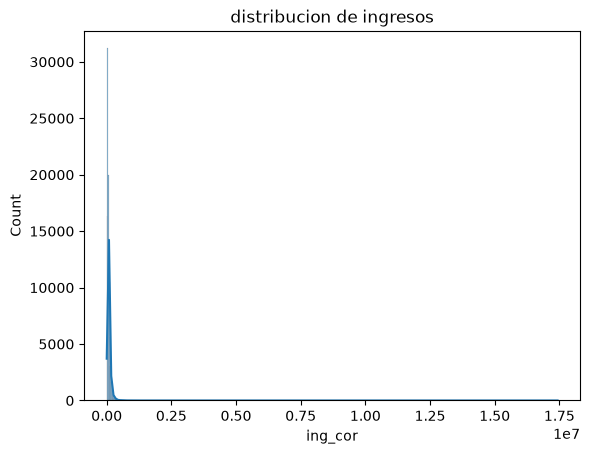

In [8]:
# Observar distribucion de ingresos (variables objetivo)

sns.histplot(hogares_eda['ing_cor'], kde=True).set_title('distribucion de ingresos')

Text(0.5, 1.0, 'Distribucion de ingresos')

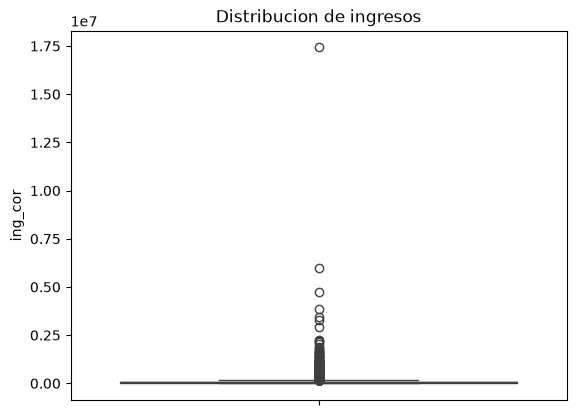

In [9]:
sns.boxplot(hogares_eda['ing_cor']).set_title('Distribucion de ingresos')

# Eliminacion de outliers

 Se observan muchos datos atipicos exageradamente altos, por lo que se procede a hacer una limpieza mediante IQR 

hasta el momento ambas bases son iguales, por lo que se les aplicara la misma limpieza

In [10]:
# Eliminacion de outliers
#cuartiles
q1 = hogares_eda['ing_cor'].quantile(0.25)
q3 = hogares_eda['ing_cor'].quantile(0.75)
# limites
lim_inf = q1 - (1.5 + (q3 - q1))
lim_sup = q3 + (1.5 + (q3 - q1))

print(f'limite superior:{lim_sup}')
print(f'limite inferior:{lim_inf}')

""" eliminar outliers, solo por encima del limite superior, 
ya que en el dataset no hay valores negativos """

hogares_eda = hogares_eda[hogares_eda['ing_cor'] < lim_sup]


limite superior:143162.0925
limite inferior:-19800.487500000003


### graficar valores limpios

In [11]:
print('========== medidas de tendencia del ingreso corriente de los hogares ======')
hogares_eda['ing_cor'].describe()

========== medidas de tendencia del ingreso corriente de los hogares ======


count     83454.000000
mean      57616.598252
std       31731.393603
min           0.000000
25%       32754.090000
50%       51577.310000
75%       77609.145000
max      143138.190000
Name: ing_cor, dtype: float64

Text(0.5, 1.0, 'distribucion de ingresos sin outliers')

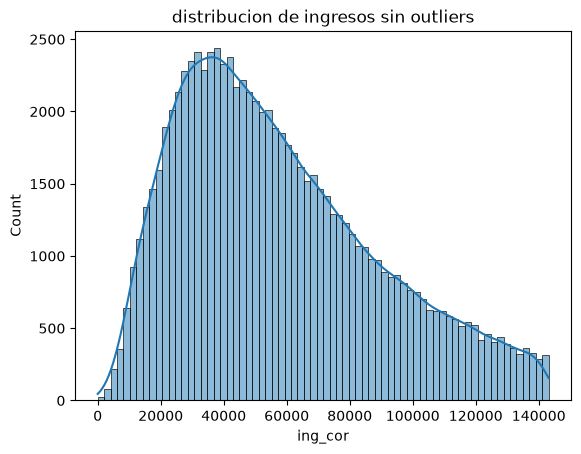

In [12]:
sns.histplot(hogares_eda['ing_cor'], kde=True).set_title('distribucion de ingresos sin outliers')

Text(0.5, 1.0, 'boxplot de ingresos sin outliers')

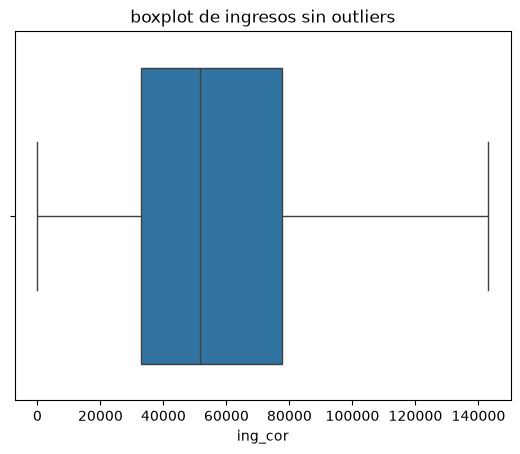

In [13]:
sns.boxplot(x=hogares_eda['ing_cor']).set_title('boxplot de ingresos sin outliers')

In [14]:
# Forma de los datasets limpios
hogares_eda.shape

(83454, 44)

# Hacer cambio de variables para analisis

de numerico a categorias

In [15]:
# Cambiar variables categoricas
hogares_eda['tam_loc'] = hogares_eda['tam_loc'].replace({1:'Mas de 100,000 hab', 2: 'De 15,000 a 99,999 hab',3: 'De 2,500 a 14,999 hab', 4: 'Menos de 2,500 hab'})
hogares_eda['est_socio'] = hogares_eda['est_socio'].replace({1:'Bajo', 2:'Medio Bajo', 3:'Medio Alto', 4:'Alto'})
hogares_eda['clase_hog'] = hogares_eda['clase_hog'].replace({1:'Unipersonal', 2: 'Nuclear', 3: 'Ampliado', 4: 'Compuesto', 5: 'Corresidente'})
hogares_eda['sexo_jefe'] = hogares_eda['sexo_jefe'].replace({1:'Hombre', 2: 'Mujer'})
hogares_eda['educa_jefe'] = hogares_eda['educa_jefe'].replace({1:'Sin Educacion', 2:'Basico', 3:'Basico', 4:'Basico', 5:'Basico', 6: 'Secundaria', 7: 'Prepa inc', 8: 'Prepa comp', 9: 'Profesional inc', 10: 'Profesional comp', 11: 'Posgrado' })
"""
Nota: estas variables se encontraban como numeros, pero eran categorias.

Posteriormente, para realizaremos una nueva base con one hot encoding para modelado de ML,
en este modelado, convertiermos tanto estas variables, como otras continuas que suman directamente al ingreso,
pero las pasaremos a esta forma para que el modelo interprete en base a su existencia y no a su valor,
ya que como se suman directo al ingreso corriente, podriamos tener problemas de multicolinealidad.
"""


'\nNota: estas variables se encontraban como numeros, pero eran categorias.\n\nPosteriormente, para realizaremos una nueva base con one hot encoding para modelado de ML,\nen este modelado, convertiermos tanto estas variables, como otras continuas que suman directamente al ingreso,\npero las pasaremos a esta forma para que el modelo interprete en base a su existencia y no a su valor,\nya que como se suman directo al ingreso corriente, podriamos tener problemas de multicolinealidad.\n'

## Analisis Inicial

Para este analisis realizaremos analisis iniciales y graficas para mostrar tendencias.

====== ingresos por tamaño de licalidad ======
tam_loc
Mas de 100,000 hab        70029.738094
De 15,000 a 99,999 hab    60909.180158
De 2,500 a 14,999 hab     54319.339798
Menos de 2,500 hab        47237.317399
Name: ing_cor, dtype: float64


Text(0.5, 1.0, 'Media de ingresos por tamaño de localidad')

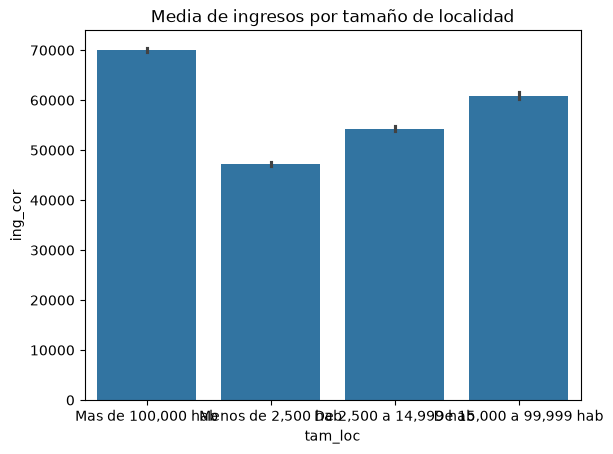

In [16]:
# tendencias ingresos por tam_loc
print('====== ingresos por tamaño de licalidad ======')
print(hogares_eda.groupby('tam_loc')['ing_cor'].mean().sort_values(ascending=False))
sns.barplot(x='tam_loc', y='ing_cor', data=hogares_eda).set_title('Media de ingresos por tamaño de localidad')

====== cantidad de hogares por tamaño de licalidad ======
tam_loc
Menos de 2,500 hab        34551
Mas de 100,000 hab        29063
De 2,500 a 14,999 hab     10239
De 15,000 a 99,999 hab     9601
Name: ing_cor, dtype: int64


Text(0.5, 1.0, 'Cantidad de hogares por tamaño de localidad')

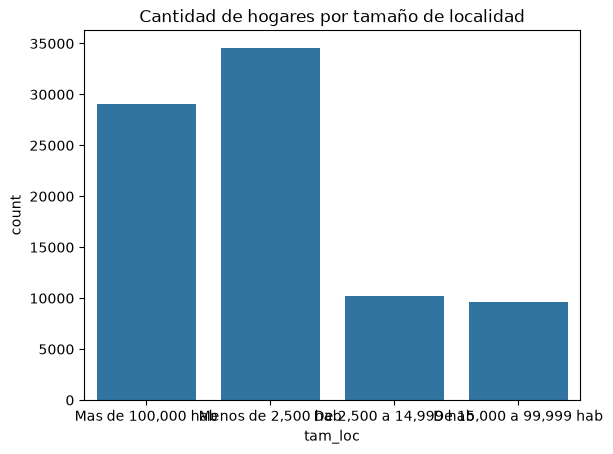

In [17]:
# cantidad de hogares por tam_loc
print('====== cantidad de hogares por tamaño de licalidad ======')
print(hogares_eda.groupby('tam_loc')['ing_cor'].count().sort_values(ascending=False))
sns.countplot(x='tam_loc', data=hogares_eda).set_title('Cantidad de hogares por tamaño de localidad')

====== ingresos promedio por estrato socioeconomico ======
est_socio
Alto          83714.849740
Medio Alto    69431.313115
Medio Bajo    56398.300344
Bajo          42865.863378
Name: ing_cor, dtype: float64


Text(0.5, 1.0, 'Tendencia de ingresos por estrato socioeconomico')

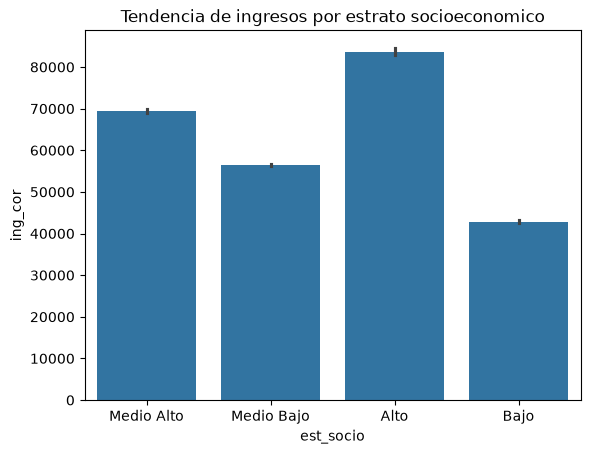

In [18]:
# tendencias de ingresos por est_socio
print('====== ingresos promedio por estrato socioeconomico ======')
print(hogares_eda.groupby('est_socio')['ing_cor'].mean().sort_values(ascending=False))
sns.barplot(x='est_socio', y='ing_cor', data=hogares_eda).set_title('Tendencia de ingresos por estrato socioeconomico')

===== cantidad de hogares por estrato socioeconomico =====
est_socio
Medio Bajo    43875
Bajo          18484
Medio Alto    15713
Alto           5382
Name: ing_cor, dtype: int64


Text(0.5, 1.0, 'Cantidad de hogares por estrato socioeconomico')

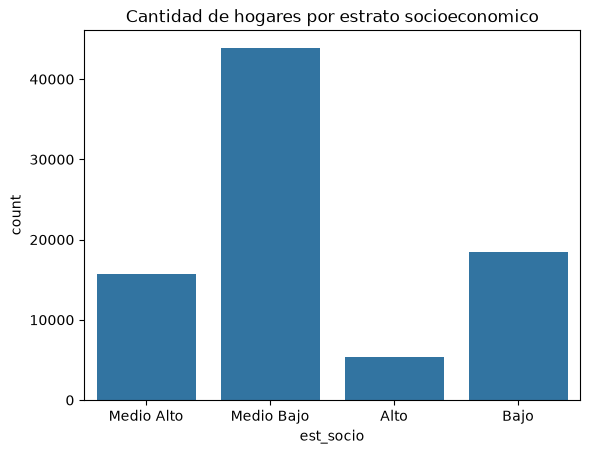

In [19]:
# cantidad de hogares por estrato socioeconomico
print('===== cantidad de hogares por estrato socioeconomico =====')
print(hogares_eda.groupby('est_socio')['ing_cor'].count().sort_values(ascending=False))
sns.countplot(x='est_socio', data=hogares_eda).set_title('Cantidad de hogares por estrato socioeconomico')


Text(0.5, 1.0, 'tendencias de ingresoso por tipo de hogar')

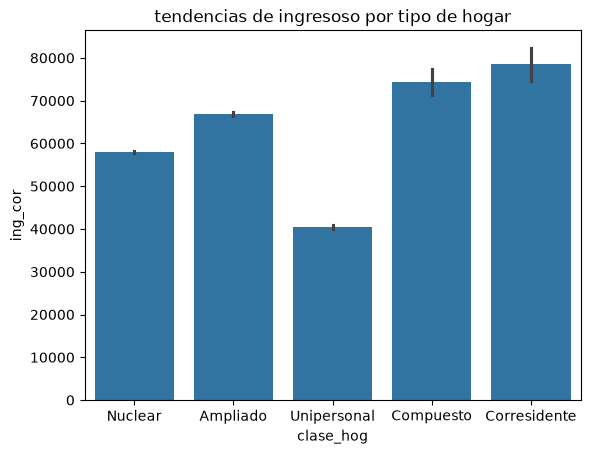

In [20]:
# tendencias de ingresos por tipo de hogar
sns.barplot(x='clase_hog', y='ing_cor', data=hogares_eda).set_title('tendencias de ingresoso por tipo de hogar')



===== cantidad de hogares por tipo de hogar =====
clase_hog
Nuclear         51443
Ampliado        19143
Unipersonal     12151
Compuesto         469
Corresidente      248
Name: ing_cor, dtype: int64


Text(0.5, 1.0, 'Cantidad de hogares por tipo de hogar')

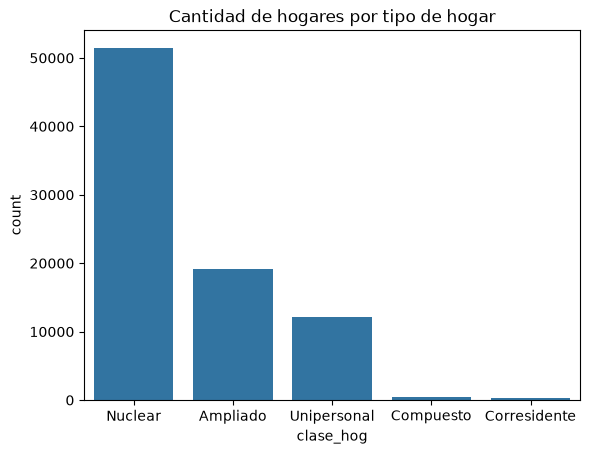

In [21]:
# Cantidad de hogares por tipo
print('===== cantidad de hogares por tipo de hogar =====')
print(hogares_eda.groupby('clase_hog')['ing_cor'].count().sort_values(ascending=False))
sns.countplot(x='clase_hog', data=hogares_eda).set_title('Cantidad de hogares por tipo de hogar')   

====== ingresos por sexo del jefe del hogar ======
sexo_jefe
Hombre    58769.150825
Mujer     55265.777218
Name: ing_cor, dtype: float64


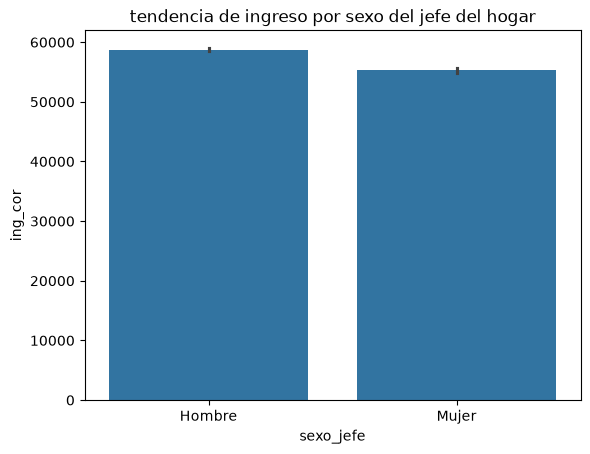

In [22]:
# ingresos por sexo del jefe del hogar
sns.barplot(x='sexo_jefe', y='ing_cor', data=hogares_eda).set_title('tendencia de ingreso por sexo del jefe del hogar')

print('====== ingresos por sexo del jefe del hogar ======')
print(hogares_eda.groupby('sexo_jefe')['ing_cor'].mean().sort_values(ascending=False))

===== cantidad de hogares por sexo del jefe del hogar =====
sexo_jefe
Hombre    55999
Mujer     27455
Name: ing_cor, dtype: int64


Text(0.5, 1.0, 'Cantidad de hogares por sexo del jefe del hogar')

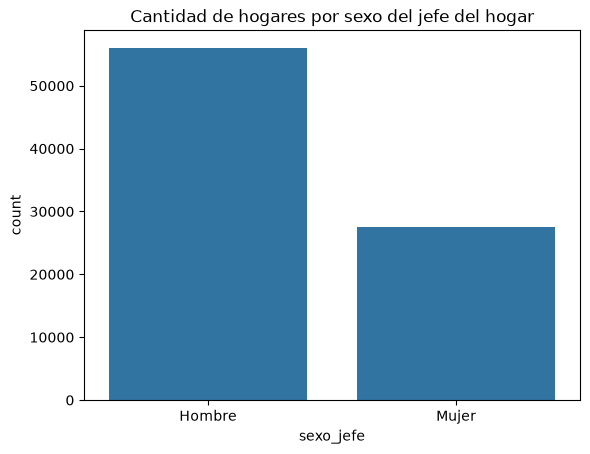

In [23]:
# cantidad de hogares por sexo del jefe del hogar
print('===== cantidad de hogares por sexo del jefe del hogar =====')
print(hogares_eda.groupby('sexo_jefe')['ing_cor'].count().sort_values(ascending=False))
sns.countplot(x='sexo_jefe', data=hogares_eda).set_title('Cantidad de hogares por sexo del jefe del hogar')

====== edad del jefe del hogar ======
count    83454.000000
mean        51.465047
std         16.168182
min         14.000000
25%         39.000000
50%         50.000000
75%         63.000000
max        106.000000
Name: edad_jefe, dtype: float64


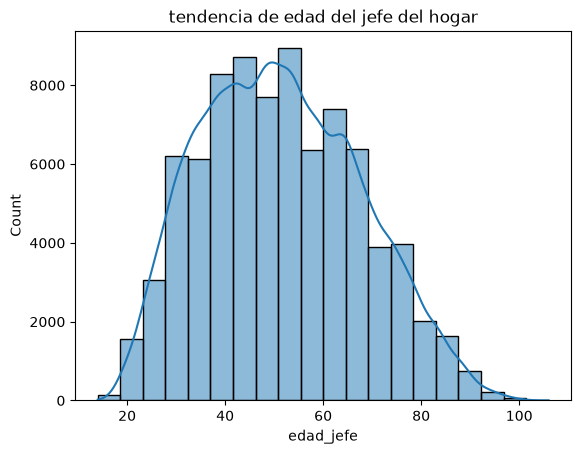

In [24]:
# tendencias de edad del jefe del hogar

sns.histplot(x='edad_jefe', data=hogares_eda, bins=20, kde=True).set_title('tendencia de edad del jefe del hogar')

print('====== edad del jefe del hogar ======')
print(hogares_eda['edad_jefe'].describe())

ingresos promedio por nivel de educacion del jefe del hogar
educa_jefe
Basico              49032.591237
Posgrado            91512.243449
Prepa comp          64819.620922
Prepa inc           61546.598747
Profesional comp    80061.237522
Profesional inc     71622.569000
Secundaria          58000.310899
Sin Educacion       40386.173418
Name: ing_cor, dtype: float64


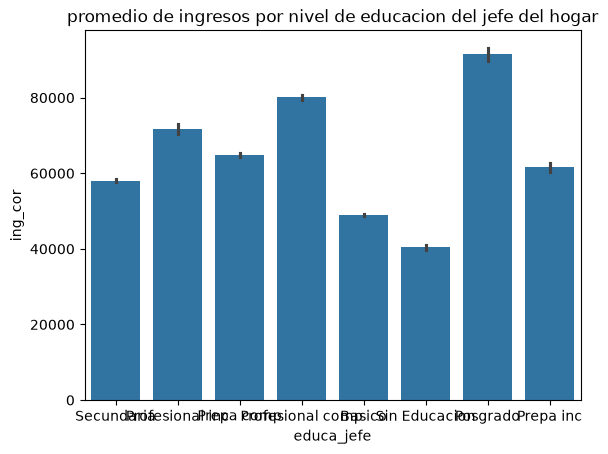

In [25]:
# Educacion del jefe del hogar
sns.barplot(x='educa_jefe', y='ing_cor', data= hogares_eda).set_title('promedio de ingresos por nivel de educacion del jefe del hogar')
print('ingresos promedio por nivel de educacion del jefe del hogar')
print(hogares_eda.groupby('educa_jefe')['ing_cor'].mean())

educa_jefe
Basico              29379
Secundaria          23446
Prepa comp          11611
Profesional comp     7533
Sin Educacion        5310
Prepa inc            2617
Profesional inc      2459
Posgrado             1099
Name: ing_cor, dtype: int64


Text(0.5, 1.0, 'Cantidad de hogares por sexo del jefe del hogar')

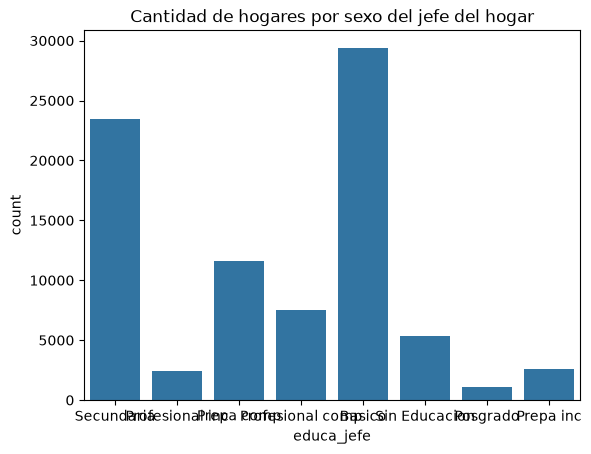

In [26]:
# cantidad de hogares por nivel de estudio del jefe del hogar 
print(hogares_eda.groupby('educa_jefe')['ing_cor'].count().sort_values(ascending=False))

sns.countplot(x='educa_jefe', data=hogares_eda).set_title('Cantidad de hogares por sexo del jefe del hogar')

count    83454.000000
mean         3.315192
std          1.726216
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         20.000000
Name: tot_integ, dtype: float64


Text(0.5, 1.0, 'Cantidad de hombres en los hogares')

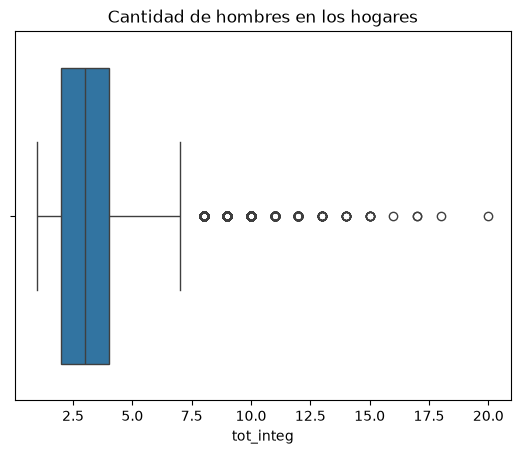

In [27]:
# numero de integrantes
print(hogares_eda['tot_integ'].describe())
sns.boxplot(x='tot_integ', data= hogares_eda).set_title('Cantidad de hombres en los hogares')

count    83454.000000
mean         1.592386
std          1.082879
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         10.000000
Name: hombres, dtype: float64


Text(0.5, 1.0, 'Cantidad de hombres en los hogares')

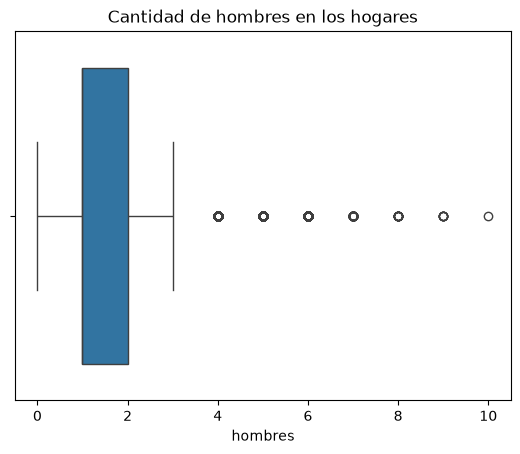

In [28]:
# Integrantes masculinos del hogar
print(hogares_eda['hombres'].describe())
sns.boxplot(x='hombres', data= hogares_eda).set_title('Cantidad de hombres en los hogares')



count    83454.000000
mean         1.722805
std          1.150927
min          0.000000
25%          1.000000
50%          2.000000
75%          2.000000
max         11.000000
Name: mujeres, dtype: float64


Text(0.5, 1.0, 'Cantidad de mujeres en los hogares')

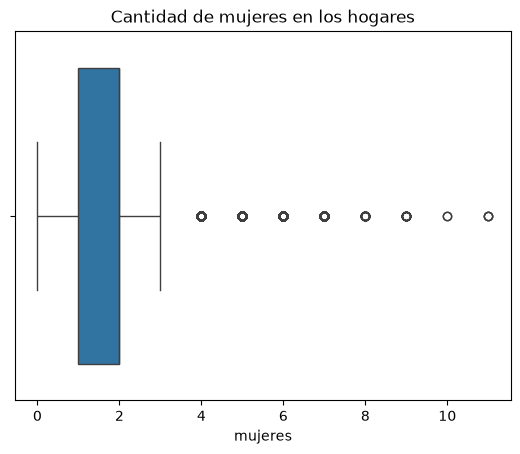

In [29]:
# Intregrantes mujeres

print(hogares_eda['mujeres'].describe())

sns.boxplot(x='mujeres', data= hogares_eda).set_title('Cantidad de mujeres en los hogares')




count    83454.000000
mean         1.573789
std          1.037695
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         11.000000
Name: ocupados, dtype: float64


Text(0.5, 1.0, 'Cantidad de personas ocupadas en los hogares')

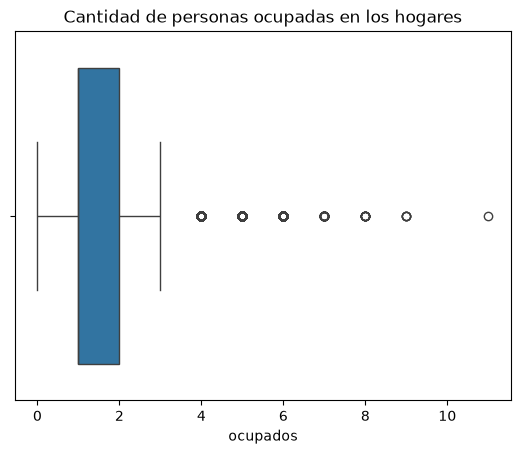

In [30]:
# personas ocupadas por hogar
print(hogares_eda['ocupados'].describe())

sns.boxplot(data= hogares_eda, x= 'ocupados').set_title('Cantidad de personas ocupadas en los hogares')

===== Personas perceptoras de ingresos =====
count    83454.000000
mean         2.127903
std          1.098368
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         13.000000
Name: percep_ing, dtype: float64


Text(0.5, 1.0, 'Distribucion de personas perceptoras de ingresos en los hogares')

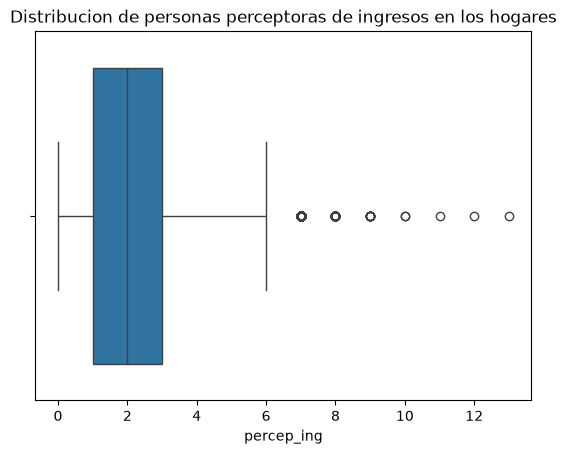

In [31]:
# personas que perciben ingreso en el hogar

print('===== Personas perceptoras de ingresos =====')
print(hogares_eda['percep_ing'].describe())

sns.boxplot(data= hogares_eda, x= 'percep_ing').set_title('Distribucion de personas perceptoras de ingresos en los hogares')

count     83454.000000
mean      28124.667655
std       27004.310697
min           0.000000
25%           0.000000
50%       23606.550000
75%       44471.540000
max      142417.570000
Name: sueldos, dtype: float64


Text(0.5, 1.0, 'Ingresos por trabajo subordinado')

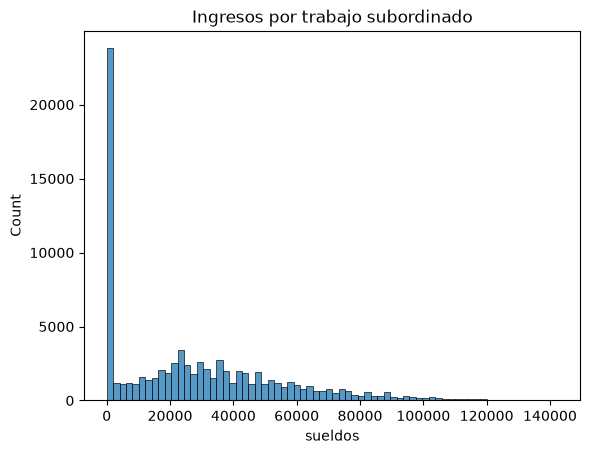

In [32]:
# Ingresos percibidos por trabajos subordinados
print(hogares_eda['sueldos'].describe())

sns.histplot(data= hogares_eda, x= 'sueldos').set_title('Ingresos por trabajo subordinado')

Text(0.5, 1.0, 'Ingresos por trabajo subordinado')

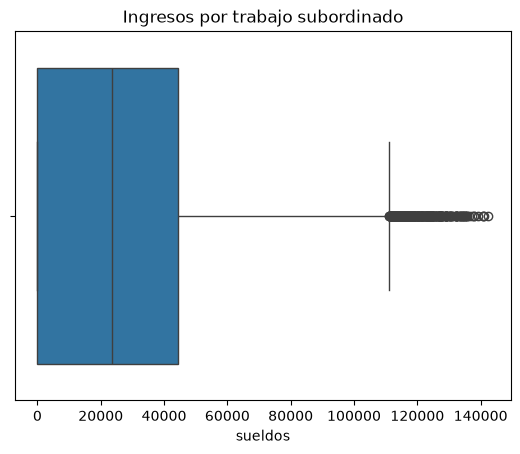

In [33]:
sns.boxplot(data= hogares_eda, x= 'sueldos').set_title('Ingresos por trabajo subordinado')

### Sobre los tipos de negocios

Las entradas son tan pocas y tan dispersas, que los graficos de barras e histogramas
resultan en lienzos en blanco, por lo que no vale la pena gastar espacio trabajando en ellos.

en su lugar para ilustrar, se utilizara la variable de negocio, que agrupa todos los tipos de negocio,

pero en conjunto tambien resultam ser demasiado dispersos y poco comunes

count     83454.000000
mean       5028.353062
std       13168.135377
min           0.000000
25%           0.000000
50%           0.000000
75%        1614.130000
max      140062.490000
Name: negocio, dtype: float64


Text(0.5, 1.0, 'Ingresos por negocios')

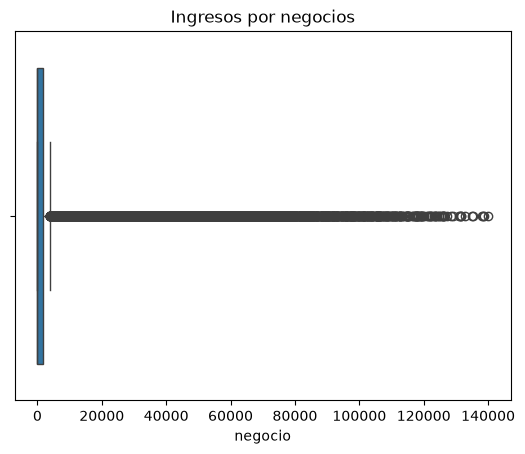

In [34]:
# Ingresos percibidos por trabajos subordinados
print(hogares_eda['negocio'].describe())

sns.boxplot(data= hogares_eda, x= 'negocio').set_title('Ingresos por negocios')

# Creación del dataset para Machine Learning

In [35]:
# Crear el datadet para ml
df_ml = hogares_eda.copy()
df_ml = df_ml.drop(columns=['trabajo', 'sueldos', 'horas_extr', 'comisiones',
        'aguinaldo', 'indemtrab', 'otra_rem', 'industria', 'comercio', 'servicios', 'agricolas', 'pecuarios',
        'reproducc', 'pesca', 'otros_trab', 'rentas', 'jubilacion', 'becas', 'donativos', 'remesas',
        'bene_gob', 'transf_hog', 'trans_inst', 'negocio'])

In [36]:
# Guardar sets de datos

df_ml.to_csv('/run/media/oswal/01DD260F5154F4B0/Duend/Documentos/1 IA y ciencia de datos/Semestre 3/proyecto integrador/Clean data/df_ml.csv', index=False, encoding='utf-8')
hogares_eda.to_csv('/run/media/oswal/01DD260F5154F4B0/Duend/Documentos/1 IA y ciencia de datos/Semestre 3/proyecto integrador/Clean data/df_eda.csv', index=False, encoding='utf-8')